# Imputation Validation


- How accurately does imputation recover measured genotypes when they are hidden?
- Masked-marker validation compares imputed and observed calls in predefined regions for 116 GSP and 48 LR.
- Genotype agreement and dosage correlation assess recovery across allele frequencies and reported confidence levels.
- These checks do not establish phase accuracy or accuracy at every unmeasured variant.


### (Initialization) Import Directory-Free Helpers

In [1]:
# Locate the repository and load shared helpers for reviewing the completed imputation outputs.

from pathlib import Path
import importlib
import sys

study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/notebook_support.py").exists())
sys.path.insert(0, str(study_root / "scripts"))
read_json = importlib.import_module("notebook_support").read_json
study_path = importlib.import_module("notebook_support").study_path
verify_datasets = importlib.import_module("notebook_support").verify_datasets
require_saved = importlib.import_module("notebook_review").require_saved
run_script = importlib.import_module("notebook_support").run_script


### Hidden Markers
- Validation hides 10% of compatible array markers in predefined regions on chromosomes 1, 3, 13, 20 and 36.
- All calls at a selected marker are hidden before phasing; masked runs do not reuse phase inferred from those calls.

### What Is Compared?
- Checks cover genotype agreement, dosage and performance by allele frequency.
- Alternate-allele carrier agreement helps avoid misleading accuracy driven by common homozygotes.

### Reference-Panel Similarity
- Measured-marker comparisons screen for unusually similar study/reference samples.
- No dog crosses the flag threshold, but relatedness or overlap is not ruled out.

### Recovery Results
- Recovery varies by region, with weaker results on chromosomes 13 and 36.
- These array checks do not establish phase accuracy or reliability at every sequence-only variant.

| Breed | Chromosome | Hidden Markers | Called Measurements | Genotype Agreement | Pooled Dosage Correlation Squared |
| :---: | :---: | :---: | :---: | :---: | :---: |
| GSP | chr1 | 61 | 7076 | 98.73% | 0.979 |
| LR | chr1 | 64 | 3069 | 98.92% | 0.985 |
| GSP | chr3 | 75 | 8695 | 99.28% | 0.991 |
| LR | chr3 | 74 | 3543 | 99.18% | 0.991 |
| GSP | chr13 | 70 | 8119 | 97.19% | 0.956 |
| LR | chr13 | 71 | 3404 | 95.42% | 0.933 |
| GSP | chr20 | 67 | 7767 | 97.32% | 0.960 |
| LR | chr20 | 68 | 3258 | 96.93% | 0.950 |
| GSP | chr36 | 61 | 7075 | 95.24% | 0.921 |
| LR | chr36 | 65 | 3117 | 95.06% | 0.927 |


### Reported Confidence Versus Measured Accuracy
- All measurable dosage correlations across 676 hidden markers are positive.
- Raising Beagle confidence improves typical recovery but retains poorly recovered markers even at 0.99.
- Measured accuracy is dosage correlation squared; 0.80 is a descriptive benchmark, not an adopted filter.

### Consequences for Association Testing
- Each breed retains 12 of 18 historical targets.
- The chromosome 6 target is retained in GSP; the first chromosome 13 target is retained in LR.
- QC exclusions remain in force.
- Primary replication uses measured calls with missing genotypes left missing.
- Imputed-only association remains deferred; historical effect matching is still needed.

| Breed | Minimum Reported Accuracy | Markers Retained | Median Measured Accuracy | Retained Markers Below 0.80 Measured Accuracy |
| :---: | :---: | :---: | :---: | :---: |
| GSP | 0.00 | 334 | 0.987 | 26 |
| GSP | 0.80 | 325 | 0.987 | 22 |
| GSP | 0.90 | 300 | 0.991 | 15 |
| GSP | 0.95 | 251 | 0.997 | 10 |
| GSP | 0.99 | 164 | 1.000 | 4 |
| LR | 0.00 | 342 | 0.988 | 36 |
| LR | 0.80 | 332 | 0.990 | 32 |
| LR | 0.90 | 302 | 0.992 | 20 |
| LR | 0.95 | 242 | 0.998 | 6 |
| LR | 0.99 | 139 | 1.000 | 3 |


### (Validation) Review Masked-Genotype Recovery

- *review_imputation.py*


In [2]:
# Require completed imputation and load or generate the hidden-marker validation review.
# The counts summarize genotype recovery and identify any reversed dosage correlations.

imputation_folder = study_root / "data/04-imputation/autosomal-20261003"
imputation = read_json(imputation_folder / "manifest.private.json")
assert imputation["status"] == "complete"
review_file = imputation_folder / "review/review.private.json"
# if not review_file.exists():
#     run_script(study_root, "review_imputation.py", "--run-dir", imputation_folder, linux=True)
review = read_json(review_file)
print("Hidden markers reviewed:", review["heldout_marker_count"])
print("Negative dosage correlations:", review["negative_correlations"])

Hidden markers reviewed: 676
Negative dosage correlations: 0


### (Visualization) Imputation Validation Charts
- Plots compare recovery across allele frequencies and contrast reported confidence with measured accuracy.
- *summarize_imputation.py*
- *plot_imputation_confidence.py*

In [3]:
# Regenerate validation figures from saved results without rerunning phasing or imputation.
# Separate figure outputs preserve the original inference files.

results_folder = study_root / "results/private/version2/05_imputation_validation"
# run_script(study_root, "summarize_imputation.py", "--run-dir", imputation_folder,
#            "--results-dir", results_folder, "--figures-only")
# run_script(study_root, "plot_imputation_confidence.py", "--run-dir", imputation_folder, "--results-dir", results_folder,
#            "--figures-only")

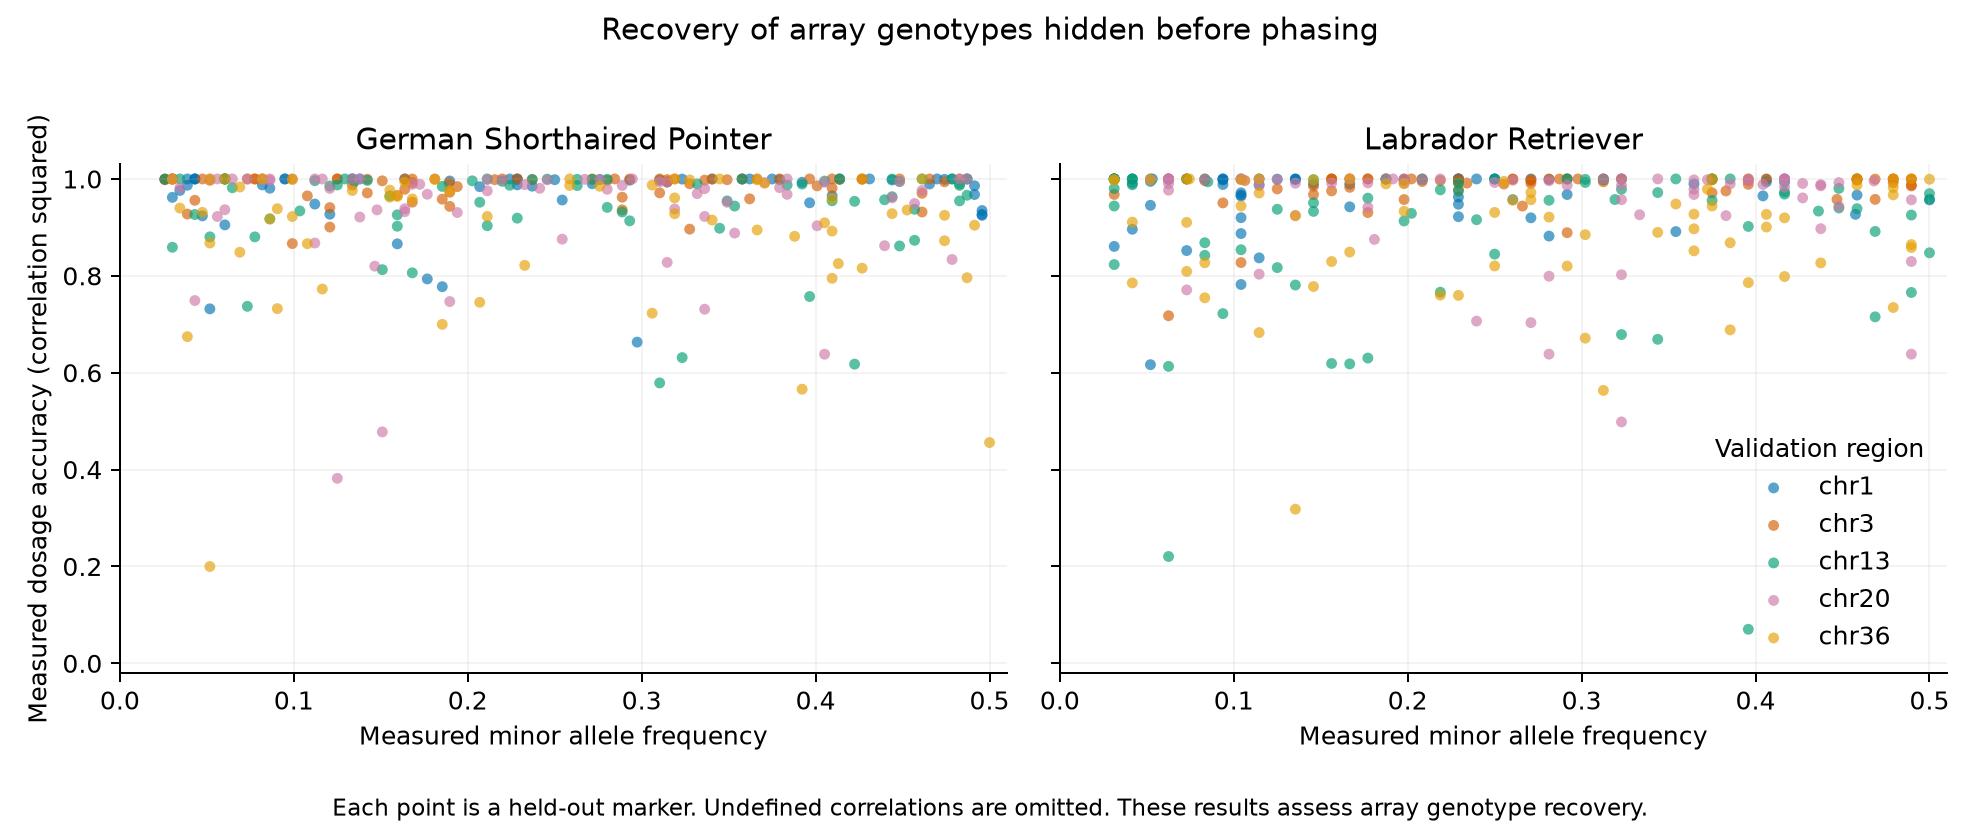

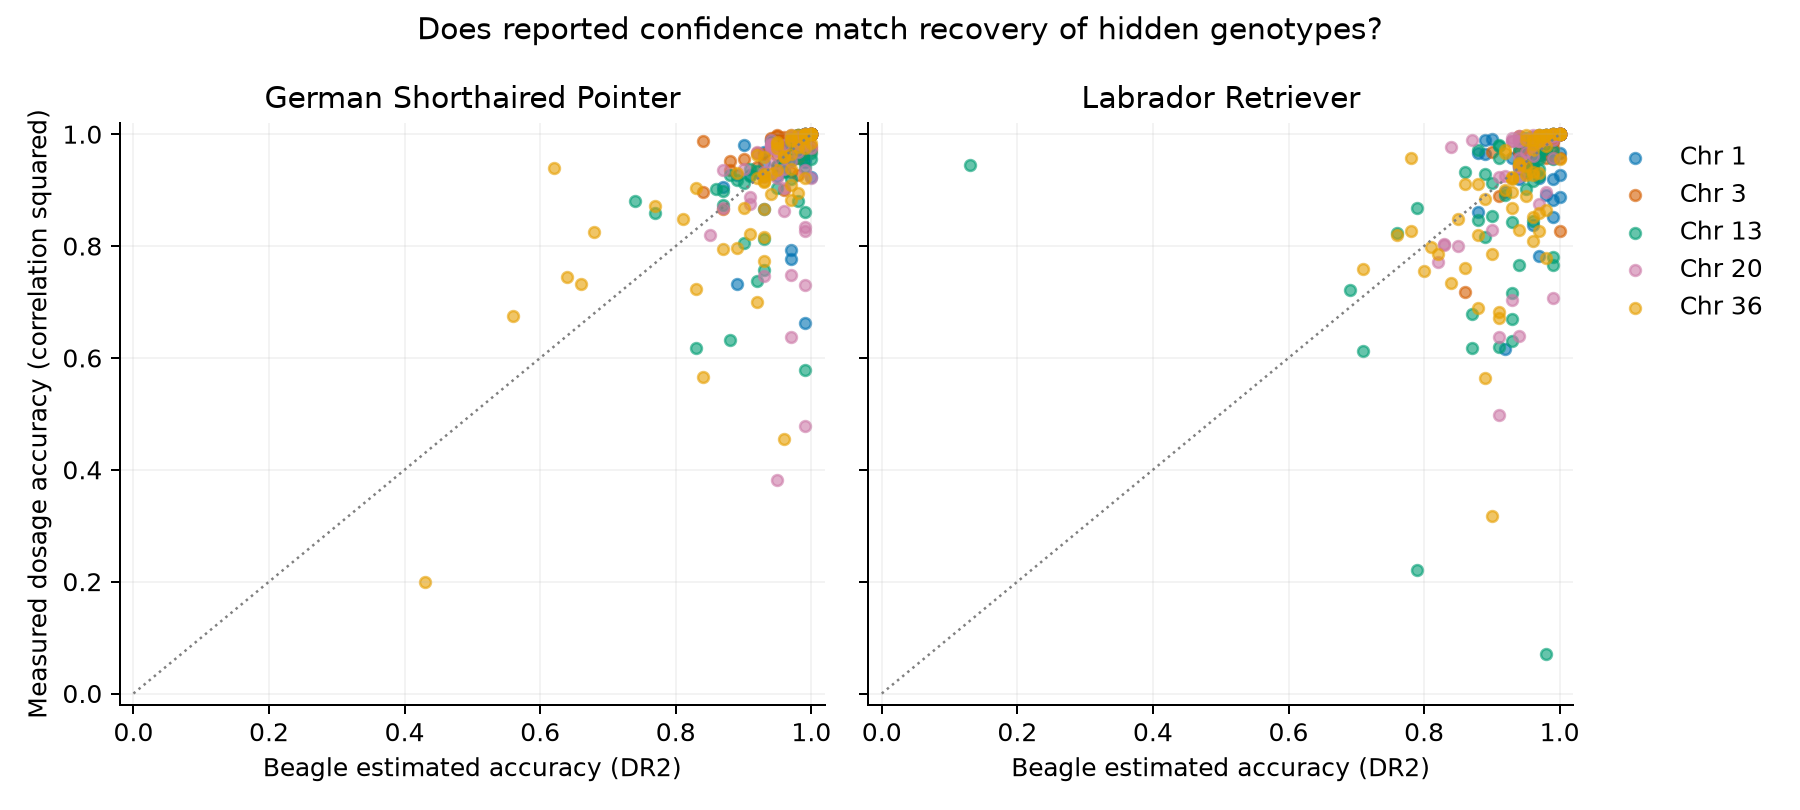

In [4]:
# Display the recovery and confidence plots to compare measured accuracy with reported confidence.

from IPython.display import Image, display
for name in ["imputation_validation", "imputation_confidence"]:
    display(Image(filename=str(results_folder / "figures" / f"{name}.png")))

### (Consistency Check) Check a Confidence Cutoff
- The code counts markers with measured accuracy below 0.80 at a reported-confidence cutoff of 0.95.

In [5]:
# Count markers retained at a reported-confidence cutoff and how many have low measured recovery.
# This checks whether a confidence filter alone removes poorly recovered validation markers.

markers = read_json(imputation_folder / "review/heldout_markers.private.json")

def compare_confidence(markers, breed, cutoff=0.95):
    kept = [m for m in markers if m["breed"] == breed
            and m["reported_DR2"] is not None and m["reported_DR2"] >= cutoff]
    measured = [m for m in kept if m["dosage_r2"] is not None]
    return {"retained": len(kept), "measurable": len(measured),
            "below_0.80": sum(m["dosage_r2"] < 0.80 for m in measured)}

for breed in ["GSP", "LR"]:
    print(breed, compare_confidence(markers, breed))

GSP {'retained': 251, 'measurable': 251, 'below_0.80': 10}
LR {'retained': 242, 'measurable': 242, 'below_0.80': 6}
